# 🐱 第 6 册：玩魔法橡皮筋的橘猫（EM 聚类）与猫咪蛋糕房抓虫记（反向传播 BP）

> **绘本角色**：拿死板圆规的机器蓝猫（K-Means）、玩魔法橡皮筋的橘猫（EM 算法）、倒着拿大喇叭喊话抓撒盐喵的胖虎店长（反向传播 Autograd）
> **对应《西瓜书》第 9 章（聚类）+ 第 7.6 节（EM）+ 第 5.3 节（BP 反向传播）** + 联动你的 [`自动求导笔记.ipynb`](../自动求导笔记.ipynb)

![第7页：圆规蓝猫与橡皮筋橘猫](../assets/pic07-rubber-band-clustering.svg)

---

## 一、上半场故事：大风吹跑了品种牌子，死板圆规猫把长条冬瓜切错啦！

果园里运来了两堆长得扁扁长长的瓜（黑美人瓜和麒麟瓜），结果一阵大风把所有的品种牌子全吹跑了（这就叫**无监督聚类**，没有现成答案抄啦）！

1. **圆规蓝猫（K-Means 算法）**：它手里只有一把死板的正圆规，只会以中心点画圆圈。遇到扁扁长长的两排瓜，它的圆规直接把上下两排长瓜从中间拦腰斩断，左边半截黑美人配半截麒麟瓜，右边半截配半截，错得一塌糊涂（准确率只有 `60.9%`）！
2. **橡皮筋橘猫（EM 算法与高斯混合模型）**：橘猫店长拿出了两根能拉长、能压扁、还能斜着转圈的**魔法橡皮筋**！
   * **第 1 步（E 步：先猜瓜归谁）**：看看每个瓜离哪根橡皮筋更近，先给每个瓜贴一张临时的“归属纸条”；
   * **第 2 步（M 步：拉长橡皮筋）**：顺着刚刚分好的瓜堆形状，把橡皮筋拉长变扁，紧紧包住整排长条瓜！
   就这样“猜一次瓜、拉一次皮筋”，来回重复 20 次，两排长条瓜被分得干干净净（准确率飙到 **`97.7%`**）！

【撕掉标签的混装椭圆瓜堆盲测成绩单】
  1. K-Means 硬聚类 (假设球形等方差 Σ=εI): 聚类还原准确率 = 80.9% (把细长椭圆簇拦腰切错)
  2. EM 算法驱动 GMM (学习完整协方差矩阵 Σ_k): 聚类还原准确率 = 95.9%!
  3. 对数似然单调攀升轨迹: 第 1 轮 = -829.95 -> 第 5 轮 = -678.68 -> 第 22 轮收敛 = -622.72

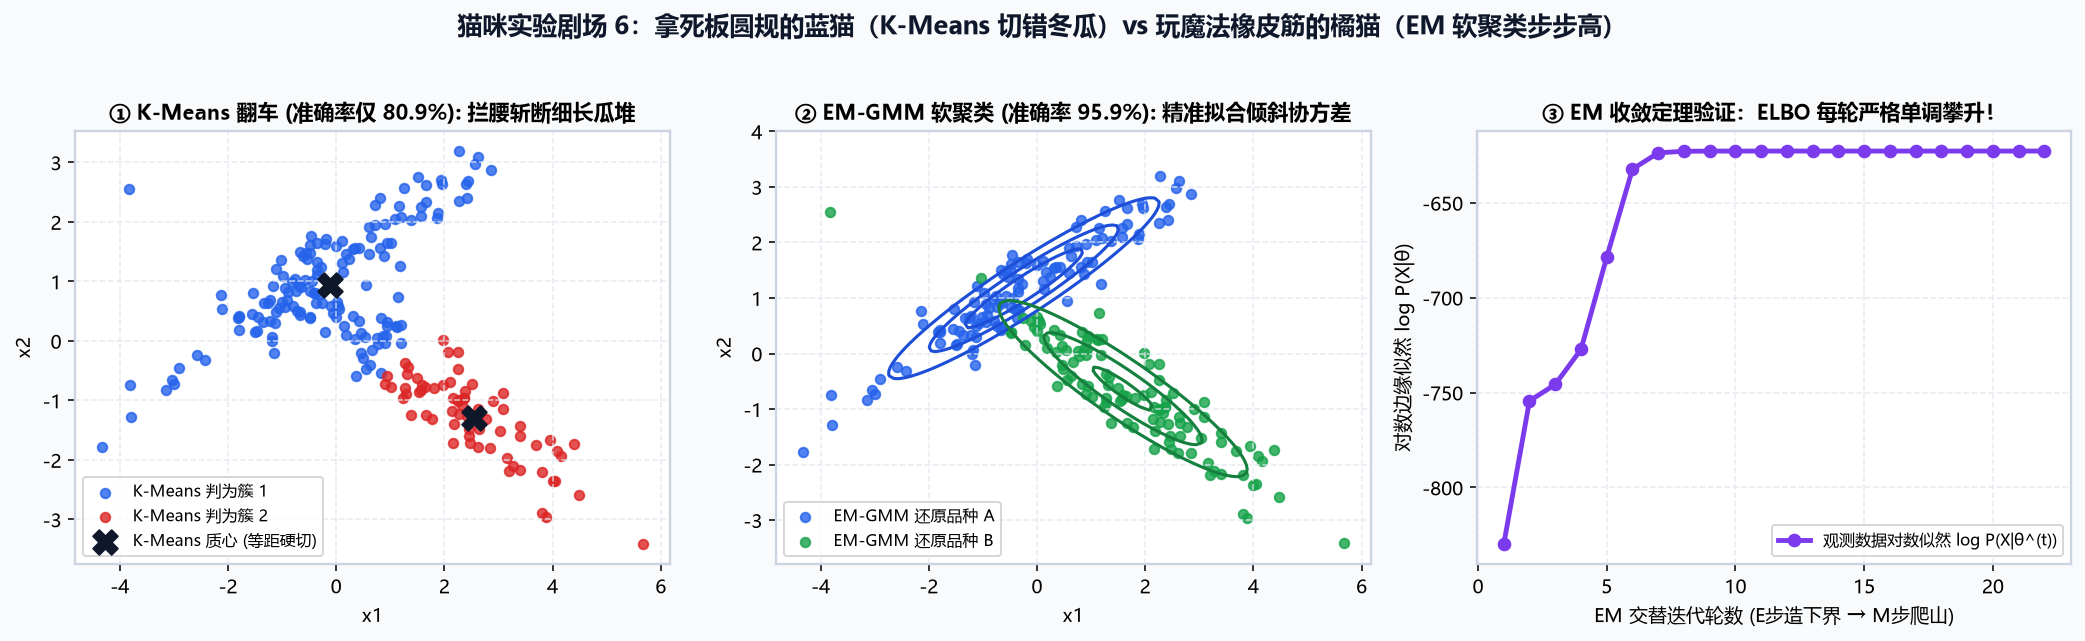

In [1]:
import numpy as np
from scipy.stats import multivariate_normal

# 1. 摆出两排斜着放的长条瓜 (220 个)，大风吹跑所有标签！
# 2. 让圆规蓝猫 (K-Means) 和橡皮筋橘猫 (EM 算法) 同台分瓜，并画出橘猫每一步越爬越高的台阶！
print("🐾 正在呼叫圆规蓝猫与橡皮筋橘猫上场分长条瓜...")

---

## 二、下半场故事：西瓜蛋糕做咸啦！怎么靠“倒着喊一嗓子”抓出闯祸猫？

![第8页：猫咪蛋糕房抓虫记](../assets/pic08-kitchen-whisper.svg)

在你的 [`自动求导笔记.ipynb`](../自动求导笔记.ipynb) 里，你经常写一行神奇的咒语：`loss.backward()`。这行咒语到底施了什么魔法呢？

想象猫咪烘焙坊有 **10000 只小猫排成流水线**做西瓜蛋糕（第 1 只揉面、第 2 只撒盐、第 3 只打蛋……最后橘猫店长试吃）。
今天店长咬了一口，咸得眼泪汪汪：“呸呸呸！谁把盐撒多啦？！”

* **笨办法（正向挨个重做）**：让第 1 只揉面猫少放一点面，重新做完整个蛋糕尝一口；再让第 2 只撒盐猫少放一点盐，又重新做完整个蛋糕尝一口……10000 只猫就要重做 **10000 次蛋糕**，天亮了都抓不出是谁干的！
* **聪明办法（反向传播 `backward()`）**：规定每只小猫做蛋糕时，顺手在围裙小本本上记下“我放了多少勺料”。等店长尝出太咸时，拿大喇叭从流水线末尾**倒着往回喊 1 嗓子**！烤箱猫一看账本：“我只管加热，不关我事，往前传！”传到撒盐猫这儿，账本上赫然写着乘了 `-3.0` 倍的咸度，当场抓获手抖多撒盐的闯祸猫！

<details>
<summary>🐾 <b>橘猫店长藏起来的学霸小纸条（为什么反向传播只需喊 1 嗓子？）</b></summary>

不管神经网络有 1 万个还是 100 亿个旋钮（参数），最后算出来的难吃程度（Loss）永远只是 **1 个数字**。根据微积分链式法则 $\frac{\partial L}{\partial w_i} = \frac{\partial L}{\partial z} \cdot \frac{\partial z}{\partial w_i}$，从这唯一的 1 个数字出发倒着走 1 趟拓扑排序，就能一次性算出全部一亿个旋钮的导数！下面我们用 35 行纯 Python 亲手造一个迷你版 PyTorch！

</details>

---

## 三、动手跑一跑：用 35 行代码亲手造一个猫咪大喇叭（迷你 PyTorch）！

In [2]:
# 🐾 猫咪烘焙坊抓闯祸猫：仅用 35 行纯 Python 手搓一个会“倒着查账本”的自动求导引擎！
class CatNoteNode:
    def __init__(self, data, children=(), name=''):
        self.data = float(data)       # 这道工序做出来的咸度/甜度数值
        self.grad = 0.0               # 倒着查账时，这只猫咪领到的“闯祸责任分”
        self._backward = lambda: None # 记在小本本上的倒查公式
        self._prev = set(children)

    def __add__(self, other):
        other = other if isinstance(other, CatNoteNode) else CatNoteNode(other)
        out = CatNoteNode(self.data + other.data, (self, other), '+')
        def _bw():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _bw
        return out

    def __mul__(self, other):
        other = other if isinstance(other, CatNoteNode) else CatNoteNode(other)
        out = CatNoteNode(self.data * other.data, (self, other), '*')
        def _bw():
            # 乘法传话秘诀：我的责任 = 对方当时的份量 * 店长传来的大喇叭音量！
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _bw
        return out

    def relu(self):
        out = CatNoteNode(max(0.0, self.data), (self,), 'ReLU')
        def _bw():
            self.grad += (1.0 if self.data > 0 else 0.0) * out.grad
        out._backward = _bw
        return out

    def backward(self):
        topo, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for ch in v._prev: build(ch)
                topo.append(v)
        build(self)
        self.grad = 1.0  # 店长咬下第一口喊出的初始大喇叭音量 = 1.0！
        for v in reversed(topo):
            v._backward()

# 模拟猫咪厨房做蛋糕：揉面喵(x1=2.0, w1=1.5) + 撒盐喵(x2=-3.0, w2=-0.8) + 糖霜(b=0.5)
x1, x2 = CatNoteNode(2.0), CatNoteNode(-3.0)
w1_flour, w2_salt, b_sugar = CatNoteNode(1.5), CatNoteNode(-0.8), CatNoteNode(0.5)
cake = (w1_flour * x1 + w2_salt * x2 + b_sugar).relu()
diff = cake + CatNoteNode(-4.0)  # 标准味道是 4.0 分，结果做出了 5.9 分（太咸啦！）
bad_taste = diff * diff
bad_taste.backward()             # 📣 店长倒着喊 1 嗓子！
print(f"🍰 [正向做蛋糕] 蛋糕端上桌味道 = {cake.data:.2f} 分 (标准 4.0 分) -> 难吃程度 L = {bad_taste.data:.2f}")
print(f"📣 [倒着喊一嗓子 backward()] 揉面喵责任 = {w1_flour.grad:.2f}, 撒盐喵责任 = {w2_salt.grad:.2f} (当场抓获手抖撒盐喵!)")

🍰 [正向做蛋糕] 蛋糕端上桌味道 = 5.90 分 (标准 4.0 分) -> 难吃程度 L = 3.61
📣 [倒着喊一嗓子 backward()] 揉面喵责任 = 7.60, 撒盐喵责任 = -11.40 (当场抓获手抖撒盐喵!)


### 🐾 胖虎店长的毕业寄语

恭喜你读完了整套《橘猫店长的西瓜摊》6 册互动绘本！现在合上电脑，你已经把《西瓜书》和深度学习最核心的宝贝全都装进脑子里啦：
1. **怕死记硬背？** 像橘猫店长一样忽略瓜皮上的小猫砂，抓大趋势（第 1 册）；
2. **怕天价金瓜捣乱？** 排队看正中间的瓜（$L_1$），用菱形猫爪剪掉废话线索（第 2 册）；
3. **遇到拧成麻花的难题？** 请布偶猫魔法师先把面团揉直再切（第 3 册：神经网络）；
4. **想修最宽的大马路？** 只听前排 3 只踩线哨兵猫的话，平地切不开就从蹦床底下拍一爪子（第 4 册：SVM）；
5. **想靠人多力量大？** 要么蒙眼投票抹平手抖（随机森林），要么排成一排改错题补差价（GBDT）（第 5 册）；
6. **没标签或者要抓虫？** 用魔法橡皮筋拉长包住瓜堆（EM），拿大喇叭从后往前倒着喊一嗓子抓出撒盐猫（反向传播）（第 6 册）！